# Spanish Springs relative hypocenters
## 1. Problem
Recover 1616 real earthquake hypocenters and origin-time corrections using 50214 observed event links/608577 differential P/S arrivals. The initial catalog is a reference prior, not ground truth. We reproduce the complete selected original hierarchical L1 case (nboot = 0) and assess all measurements without forcing its final clustering identity. Source reference arrays are independently executed method results, never independently known locations.

In [1]:
from pathlib import Path
import sys,json,time,subprocess
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
T=Path.cwd()
if T.name=='notebooks':T=T.parent
sys.path.insert(0,str(T))
from src.preprocessing import load,algorithm_inputs
from src.solvers import reconstruct
from src.physics_model import physical_residuals,physical_metrics,observation_components
from src.visualization import catalog_maps,local_coordinates
D=load(T/'data/raw_data.npz');initial=D['initial_catalog'];labels=observation_components(D);ids=np.flatnonzero(labels==np.argmax(np.bincount(labels)));reference=initial[ids,:2].mean(0)
with np.load(T/'notebooks/reference_outputs/upstream_catalog.npz') as f:source=f['reconstruction'][0].copy()
def table(headers,rows):display(Markdown('| '+' | '.join(headers)+' |\n|'+'|'.join(['---']*len(headers))+'|\n'+'\n'.join('| '+' | '.join(str(x) for x in row)+' |' for row in rows)))


## 2. Data and legitimate response calibration
Native decimal observations remain float64 on disk. The independent one-dimensional velocity model supplies a101×27×2 P/S travel-time table at native float32 precision; it is not estimated from final hypocenters. Source code internally uses mixed float64 geographic coordinates and float32 depth/time/calibration arithmetic. We preserve that convention, including original heap-order ties and sequential sums. Geographic degrees, kilometres and seconds remain distinct.

An independent ideal vertical-ray check initially exposed a≈47 microsecond P discrepancy: original float32 spherical-to-flat-Earth transformation has shallow-layer cancellation. Independent quadrature through that actual finite-precision calibration agrees within 2 microseconds; the ideal physical model difference lies below the Earth-radius float32 roundoff budget. The table is an approximate known response, not claimed exact continuous-Earth truth. S speeds are derived by1.732 and serialized to four decimals before original ray calibration.

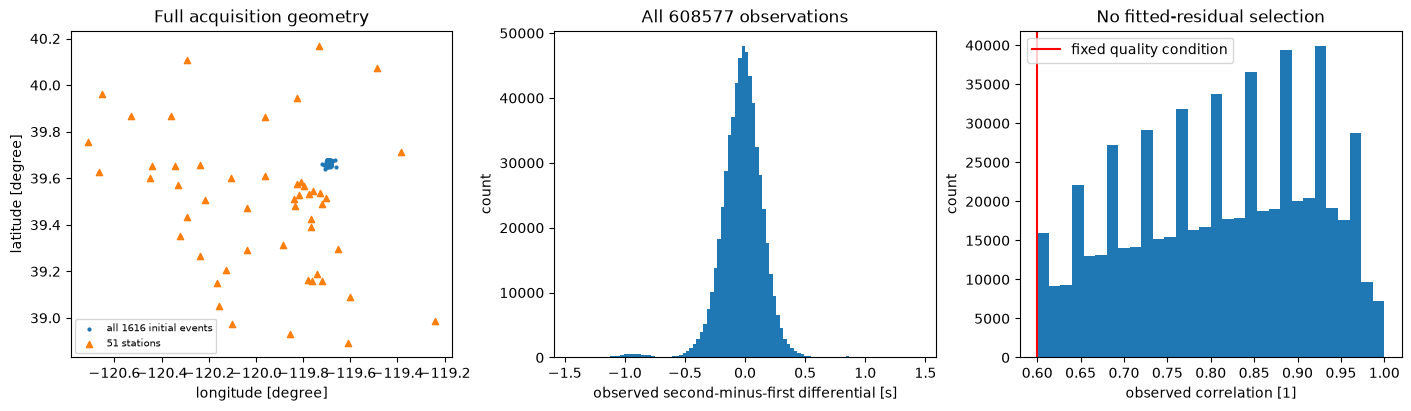

| Quantity | Count/shape | Unit |
|---|---|---|
| events | 1616 | 1 |
| observed pairs | 50214 | 1 |
| observations | 608577 | 1 |
| known travel-time table | (101, 27, 2) | s |
| public graph components | 818 | 1 |

In [2]:
fig,ax=plt.subplots(1,3,figsize=(14,4),layout='constrained');ax[0].scatter(initial[:,1],initial[:,0],s=4,label='all 1616 initial events');ax[0].scatter(D['station_positions'][:,1],D['station_positions'][:,0],marker='^',s=20,label='51 stations');ax[0].set(xlabel='longitude [degree]',ylabel='latitude [degree]',title='Full acquisition geometry');ax[0].legend(fontsize=7)
ax[1].hist(D['differential_times'],bins=100);ax[1].set(xlabel='observed second-minus-first differential [s]',ylabel='count',title='All 608577 observations')
ax[2].hist(D['cross_correlation'],bins=30);ax[2].axvline(.6,color='red',label='fixed quality condition');ax[2].set(xlabel='observed correlation [1]',ylabel='count',title='No fitted-residual selection');ax[2].legend();plt.show()
table(['Quantity','Count/shape','Unit'],[['events',len(initial),'1'],['observed pairs',len(D['event_pairs']),'1'],['observations',len(D['differential_times']),'1'],['known travel-time table',D['travel_time_table'].shape,'s'],['public graph components',len(np.unique(labels)),'1']])


## 3. Physics and fair conditional target
For event pair i, j, station s and P/S phase p,
$$
b_{ijsp}=T_p(r_{js},z_j)+h_j-T_p(r_{is},z_i)-h_i+e_{ijsp}.
$$
Here b, T, h, e are seconds, depth z and range r are kilometres; latitude/longitude are degrees. The positive origin correction h makes an event later. Ranges use a fixed local geographic convention with pair-mean event latitude, and T is the supplied bilinear/zero-corner-extrapolated table response. Calibration is independent of the relocated catalog.

The public quality mask is determined only by observed correlation≥0.6 and initial pair-centroid/station range≤80 km. It includes 575672 observations. Each phase is evaluated by its mean absolute residual:
$$
J_p=\frac{1}{M_p}\sum_{k\in\mathcal{M}_p}|b_k-\widehat b_k|.
$$
Here M(p) is the number of qualified observations of phase p, the set M(p) contains exactly those observation indices, and the hat denotes the declared forward prediction. All full-observation-graph components additionally retain the initial catalog centroid and zero mean h. These are conditional spatial priors and the exact differential-time origin gauge respectively. Spatial translation with fixed stations is not an exact invariance. No hidden final clusters define the graph or mask. Four output quantities are latitude/longitude degrees, depthkm, time correction in seconds. No actual final-location truth is available.

| Actual measurement | P MAE [s] | S MAE [s] | maximum component centroid [km] | maximum component mean time [s] |
|---|---|---|---|---|
| initial catalog | 0.0942144247012 | 0.0977015600982 | 0 | 0 |
| actual original fullcase | 0.0201002285343 | 0.0170586319313 | 3.1974978913e-06 | 5.27095899247e-08 |

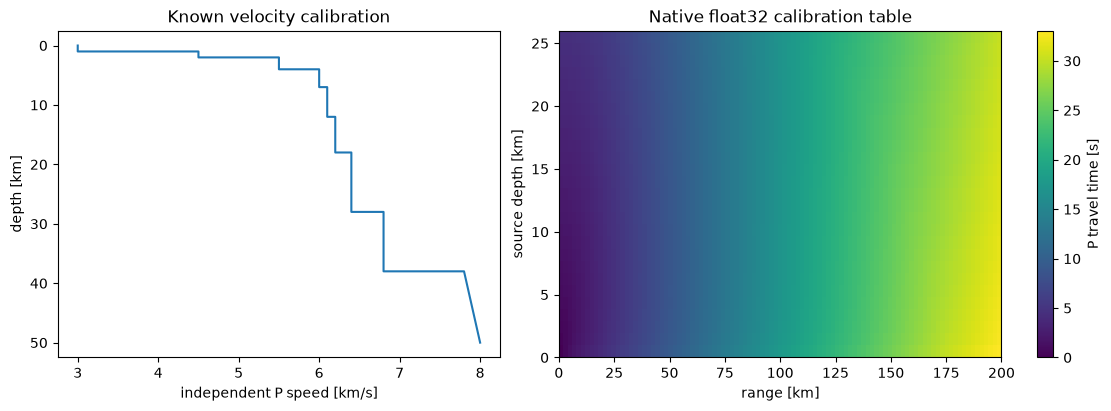

In [3]:
m_initial=physical_metrics(D,initial);m_source=physical_metrics(D,source);table(['Actual measurement','P MAE [s]','S MAE [s]','maximum component centroid [km]','maximum component mean time [s]'],[[name]+[f'{m[k]:.12g}' for k in m] for name,m in [('initial catalog',m_initial),('actual original fullcase',m_source)]])
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained');ax[0].plot(D['velocity_model'][:,1],D['velocity_model'][:,0]);ax[0].invert_yaxis();ax[0].set(xlabel='independent P speed [km/s]',ylabel='depth [km]',title='Known velocity calibration');a=ax[1].imshow(D['travel_time_table'][:,:,0].T,origin='lower',aspect='auto',extent=[0,200,0,26]);fig.colorbar(a,ax=ax[1],label='P travel time [s]');ax[1].set(xlabel='range [km]',ylabel='source depth [km]',title='Native float32 calibration table');plt.show()


## 4. Method and complete active reconstruction
Start one cluster per event, prioritize pairs by observed waveform similarity, and consider up to ten strongest remaining intercluster links. A complete relative 3 D grid search keeps each group's internal positions fixed. For a spatial trial, let a be observed-minus-predicted differential residuals before a new relative time shift. The minimizing shift for L1 is
$$
\Delta h=\operatorname{median}(a),\qquad F=\sum_k |a_k-\Delta h|.
$$
Search 27 symmetric centroid trials per iteration, shrink the box by0.67 and use 15 iterations. Apply original residual/separation/centroid-shift acceptance controls; after each accepted merge restore its original catalog centroid and mean timezero. Every 50214 pair is processed. This is explicit local NumPy mathematics, with no domain relocation solver. The selected source has bootstrap disabled, so no location confidence intervals are claimed.

Actual complete standard: seconds 44.22975629998837 accepted merges 728 trial attempts 3855


| Quantity | Fresh versus original maximum | Unit |
|---|---|---|
| latitude | 0.0 | degree |
| longitude | 0.0 | degree |
| depth | 0.0 | km |
| origin correction | 0.0 | s |

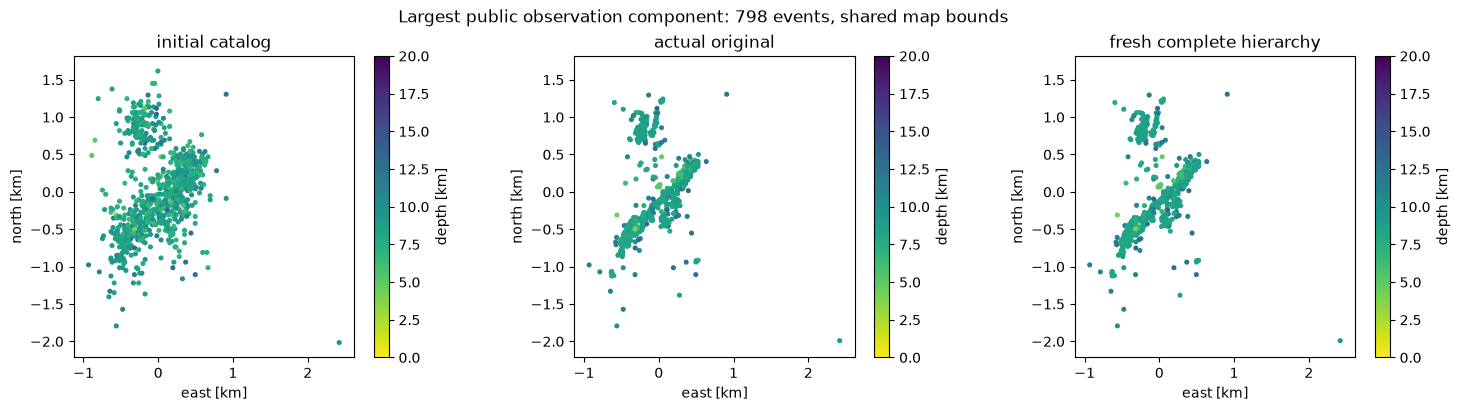

In [4]:
t=time.perf_counter();fresh,aux=reconstruct(D);runtime=time.perf_counter()-t;q=fresh['reconstruction'][0];(T/'output').mkdir(exist_ok=True);np.savez(T/'output/reconstruction.npz',**fresh);print('Actual complete standard: seconds',runtime,'accepted merges',len(aux['accepted']),'trial attempts',int(aux['attempts']))
table(['Quantity','Fresh versus original maximum','Unit'],[[name,np.max(np.abs(q[:,k]-source[:,k])),unit] for k,(name,unit) in enumerate([('latitude','degree'),('longitude','degree'),('depth','km'),('origin correction','s')])])
catalog_maps(D,{'initial catalog':initial,'actual original':source,'fresh complete hierarchy':q},labels,'Largest public observation component: 798 events, shared map bounds');plt.show()


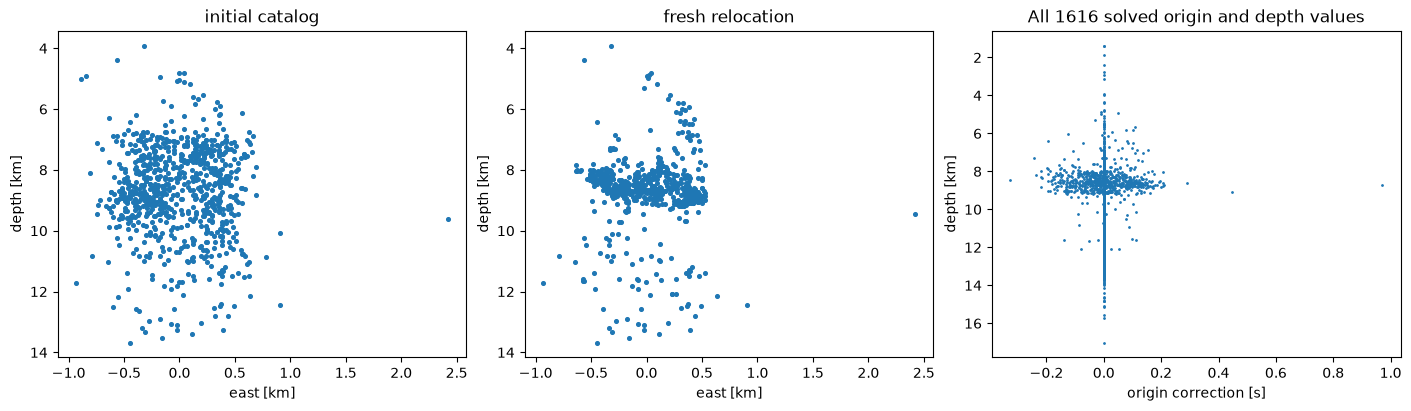

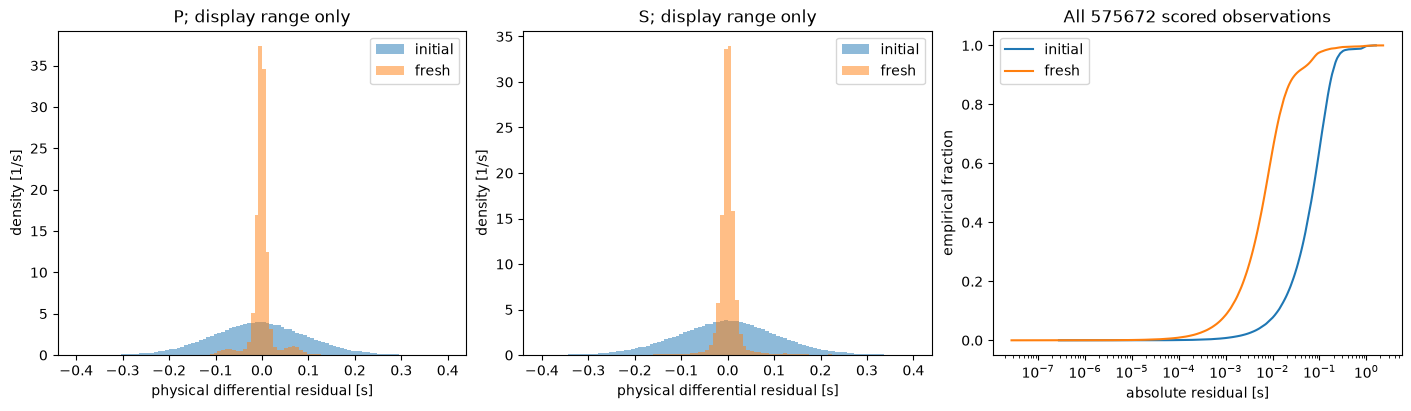

| Measurement | P MAE [s] | S MAE [s] | centroid bound diagnostic [km] | mean-time diagnostic [s] |
|---|---|---|---|---|
| actual original | 0.0201002285343 | 0.0170586319313 | 3.1974978913e-06 | 5.27095899247e-08 |
| fresh local | 0.0201002285343 | 0.0170586319313 | 3.1974978913e-06 | 5.27095899247e-08 |

In [5]:
xy=local_coordinates(q,reference);x0=local_coordinates(initial,reference);fig,ax=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for a,xx,label in [(ax[0],x0,'initial catalog'),(ax[1],xy,'fresh relocation')]:a.scatter(xx[ids,0],initial[ids,2] if label=='initial catalog' else q[ids,2],s=7);a.invert_yaxis();a.set(xlabel='east [km]',ylabel='depth [km]',title=label)
ax[2].plot(q[:,3],q[:,2],'.',ms=2);ax[2].invert_yaxis();ax[2].set(xlabel='origin correction [s]',ylabel='depth [km]',title='All 1616 solved origin and depth values');plt.show()
r0,mask=physical_residuals(D,initial);rf,_=physical_residuals(D,q);fig,ax=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for phase,name,a in [(1,'P',ax[0]),(2,'S',ax[1])]:
 selected=mask&(D['phase']==phase);a.hist(r0[selected],bins=100,range=(-.4,.4),alpha=.5,density=True,label='initial');a.hist(rf[selected],bins=100,range=(-.4,.4),alpha=.5,density=True,label='fresh');a.set(xlabel='physical differential residual [s]',ylabel='density [1/s]',title=name+'; display range only');a.legend()
for residual,name in [(r0,'initial'),(rf,'fresh')]:values=np.sort(np.abs(residual[mask]));ax[2].plot(values,np.arange(1,len(values)+1)/len(values),label=name)
ax[2].set(xlabel='absolute residual [s]',ylabel='empirical fraction',title='All 575672 scored observations');ax[2].set_xscale('log');ax[2].legend();plt.show()
table(['Measurement','P MAE [s]','S MAE [s]','centroid bound diagnostic [km]','mean-time diagnostic [s]'],[[name]+[f'{m[k]:.12g}' for k in m] for name,m in [('actual original',m_source),('fresh local',physical_metrics(D,q))]])


## 5. Actual comparisons and perturbation sensitivity
Actively reconstruct every event again with a higher 0.8 correlation condition for pair ORDERING, and with only 8 search iterations. Both still evaluate the same fixed public measurement mask and full graph anchors. These are diagnostic method variants, not new physical measurement definitions. Then run the complete 15-iteration method on data perturbed by one 1 ms Gaussian arrival-difference realization. Assess its forward residual on both its own noisy observations and the original bound observations. Differences from the standard catalog are sensitivity diagnostics, not errors against unknown true hypocenters or the optional published bootstrap uncertainty estimate.

Three complete diagnostic inversions: seconds 119.36062900000252


| Actual complete inverse | Bound P MAE [s] | Bound S MAE [s] | Own-data P MAE [s] | Own-data S MAE [s] |
|---|---|---|---|---|
| standard (15 iterations) | 0.0201002285 | 0.0170586319 | 0.0201002285 | 0.0170586319 |
| higher quality ordering | 0.0195527467 | 0.0161211098 | 0.0195527467 | 0.0161211098 |
| coarse grid (8 iterations) | 0.0266289268 | 0.0325932463 | 0.0266289268 | 0.0325932463 |
| 1 ms perturbed data | 0.0199929019 | 0.0171556941 | 0.0200363505 | 0.017189566 |

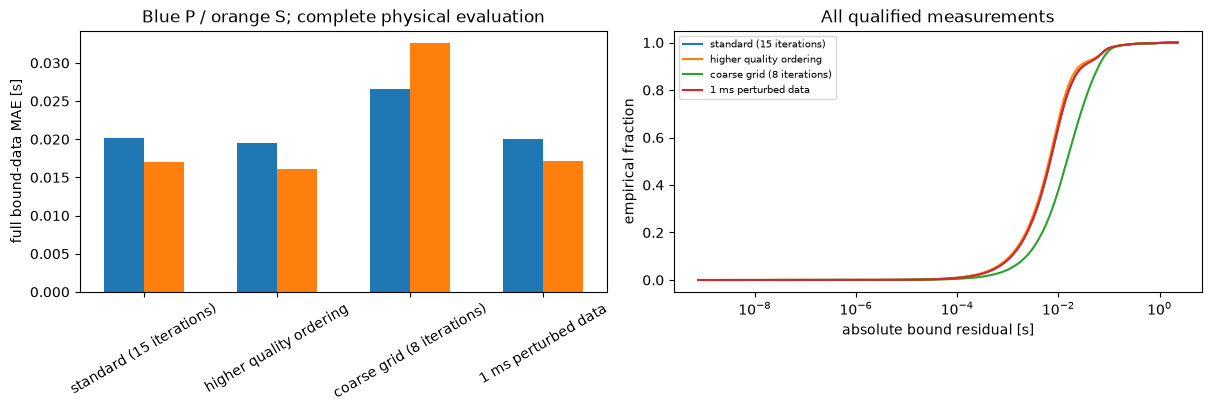

In [6]:
t=time.perf_counter();high,_=reconstruct(D,rmin=.8);coarse,_=reconstruct(D,nit=8);rng=np.random.default_rng(17);noisyD={**D,'differential_times':D['differential_times']+rng.normal(0,.001,D['differential_times'].shape)};noisy,_=reconstruct(noisyD);print('Three complete diagnostic inversions: seconds',time.perf_counter()-t)
methods={'standard (15 iterations)':q,'higher quality ordering':high['reconstruction'][0],'coarse grid (8 iterations)':coarse['reconstruction'][0],'1 ms perturbed data':noisy['reconstruction'][0]};rows=[]
for name,z in methods.items():
 m=physical_metrics(D,z);own=physical_metrics(noisyD,z) if name=='1 ms perturbed data' else m;rows.append([name,f'{m["p_mean_absolute_residual_s"]:.9g}',f'{m["s_mean_absolute_residual_s"]:.9g}',f'{own["p_mean_absolute_residual_s"]:.9g}',f'{own["s_mean_absolute_residual_s"]:.9g}'])
table(['Actual complete inverse','Bound P MAE [s]','Bound S MAE [s]','Own-data P MAE [s]','Own-data S MAE [s]'],rows)
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for i,(name,z) in enumerate(methods.items()):
 m=physical_metrics(D,z);ax[0].bar(i-.15,m['p_mean_absolute_residual_s'],.3,color='tab:blue');ax[0].bar(i+.15,m['s_mean_absolute_residual_s'],.3,color='tab:orange');res,_=physical_residuals(D,z);values=np.sort(np.abs(res[mask]));ax[1].plot(values,np.arange(1,len(values)+1)/len(values),label=name)
ax[0].set(xticks=np.arange(len(methods)),xticklabels=list(methods),ylabel='full bound-data MAE [s]',title='Blue P / orange S; complete physical evaluation');ax[0].tick_params(axis='x',rotation=30);ax[1].set(xlabel='absolute bound residual [s]',ylabel='empirical fraction',title='All qualified measurements');ax[1].set_xscale('log');ax[1].legend(fontsize=7);plt.show()


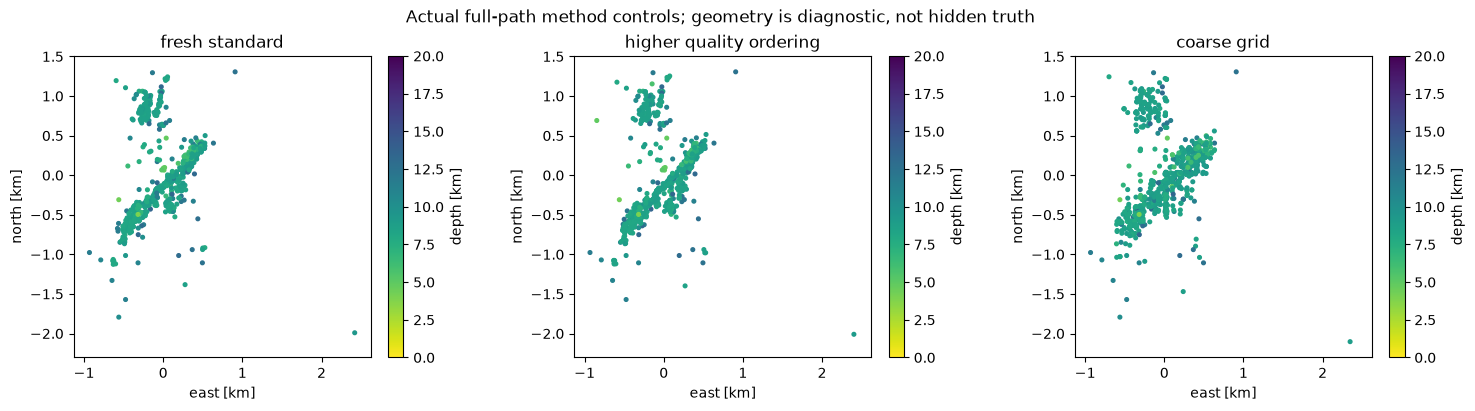

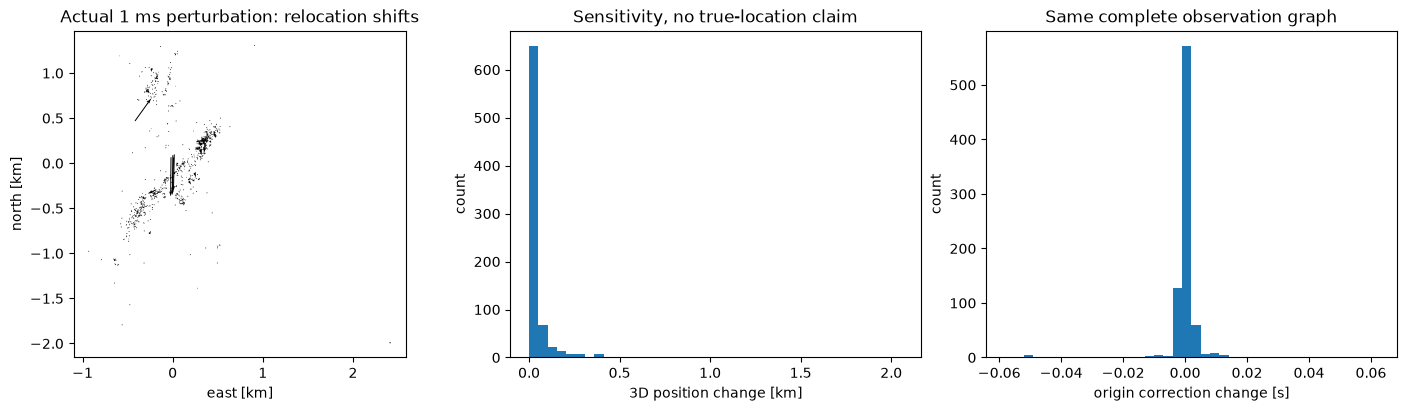

In [7]:
catalog_maps(D,{'fresh standard':q,'higher quality ordering':methods['higher quality ordering'],'coarse grid':methods['coarse grid (8 iterations)']},labels,'Actual full-path method controls; geometry is diagnostic, not hidden truth');plt.show()
noiseq=methods['1 ms perturbed data'];delta=local_coordinates(noiseq,reference)-local_coordinates(q,reference);distance=np.sqrt(np.sum(delta*delta,axis=1)+(noiseq[:,2]-q[:,2])**2);fig,ax=plt.subplots(1,3,figsize=(14,4),layout='constrained');ax[0].quiver(xy[ids,0],xy[ids,1],delta[ids,0],delta[ids,1],angles='xy',scale_units='xy',scale=1,width=.003);ax[0].set(xlabel='east [km]',ylabel='north [km]',title='Actual 1 ms perturbation: relocation shifts');ax[0].set_aspect('equal');ax[1].hist(distance[ids],bins=40);ax[1].set(xlabel='3D position change [km]',ylabel='count',title='Sensitivity, no true-location claim');ax[2].hist(noiseq[ids,3]-q[ids,3],bins=40);ax[2].set(xlabel='origin correction change [s]',ylabel='count',title='Same complete observation graph');plt.show()


## 6. Conclusion and final evaluation
The fresh full hierarchy exactly matches the independently captured original mixed-precision result and reduces physical P/S residuals substantially compared with the initial catalog. The fair benchmark evaluates all qualified arrivals and public graph anchors, allowing other valid inverse solutions. Sharper spatial geometry does not establish absolute fault accuracy: the velocity calibration is approximate, true event locations are unavailable, and catalog centroids are conditional priors. Source algorithm-specific clusters are neither supplied as input nor required in the Judge. Standard selected nboot = 0 does not provide formal bootstrap confidence limits. All plotted variants were computed; archived original results are separately labeled.

In [8]:
r=subprocess.run([sys.executable,str(T/'evaluation/judge.py'),'--prediction',str(T/'output/reconstruction.npz'),'--report',str(T/'output/judge_report.json')],cwd=T,capture_output=True,text=True,encoding='utf8');print((T/'output/judge_report.json').read_text(encoding='utf8'));assert r.returncode==0,r.stderr


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "p_mean_absolute_residual_s": 0.020100228534259745,
    "s_mean_absolute_residual_s": 0.017058631931293554,
    "maximum_component_centroid_offset_km": 3.1974978912962984e-06,
    "maximum_component_mean_origin_correction_s": 5.2709589924728664e-08
  },
  "thresholds": {
    "p_mean_absolute_residual_s": {
      "comparison": "<=",
      "boundary": 0.020105228534259747
    },
    "s_mean_absolute_residual_s": {
      "comparison": "<=",
      "boundary": 0.017063631931293555
    },
    "maximum_component_centroid_offset_km": {
      "comparison": "<=",
      "boundary": 5e-05
    },
    "maximum_component_mean_origin_correction_s": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": []
}


The historical paper additionally compares a separate HypoDD LSQR implementation and performs a100-resample location-uncertainty study. Those historical numbers are not substituted for fresh measurements here. The bound selected author-distributed experiment is the full GrowClust example with bootstrap disabled; this Notebook shows actual full-path quality, discretization and data-perturbation comparisons instead. It does not claim reproduction of the historical HypoDD run or formal bootstrap error bars.